# Milestone M2.0 — Reproducible Baseline Model Comparison
## Project: Recut Research Lab 01 — Advertising Consistency & Claim Verification

---

## 1. Research Objective

Before investing in hyperparameter search, neural cross-encoders, or domain transfer, empirical machine learning requires **reproducible, unoptimized baseline measurements**. Baselines establish transparent lower bounds, verify pipeline integrity, surface shortcut signals via diagnostic controls, and provide fixed reference points for subsequent research hypotheses.

In **Milestone M2.0**, we train and evaluate four CPU-compatible baseline configurations (`B0`–`B3`) on the official CyberAgent AdTEC `ad-consistency` benchmark using strictly controlled training and validation splits.

> [!IMPORTANT]
> **Task Boundary and Scientific Scope**:
> - This benchmark evaluates **binary consistency** (`consistent` vs. `inconsistent`) between Japanese search engine advertising titles (`title`) and landing-page texts (`lp_text`).
> - It does **NOT** evaluate factual correctness, medical or clinical truth, or skincare efficacy claims.
> - M2.0 establishes reference measurements only; it does **not** answer RQ1 (unseen landing-page generalization), RQ2 (lexical vs. semantic modeling), or RQ3 (annotation noise sensitivity).

In [1]:
# Configure environment, imports, and Japanese-inspired research color palette
import json
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Resolve repository root and ensure src/ is importable
REPO_ROOT = Path("..").resolve()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from recut_lab.analysis import build_error_inspection_table
from recut_lab.baseline import M2_DEFAULT_CONFIG, run_m2_baseline_benchmark
from recut_lab.data import load_adtec_train_valid
from recut_lab.evaluation import LABEL_ORDER

# Display full Japanese text without truncation during qualitative inspection
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)

# Japanese-inspired academic color palette
IVORY = "#F7F3EA"
INDIGO = "#33415C"
VERMILION = "#C65D4B"
MATCHA = "#71816D"
GRAY = "#8A8A86"

# Configure Matplotlib typography and figure styling
mpl.rcParams["font.sans-serif"] = [
    "Meiryo", "Yu Gothic", "MS Gothic", "Noto Sans CJK JP",
    "TakaoPGothic", "DejaVu Sans", "sans-serif",
]
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.facecolor"] = IVORY
mpl.rcParams["axes.facecolor"] = IVORY
mpl.rcParams["axes.edgecolor"] = GRAY
mpl.rcParams["grid.color"] = GRAY

FIGURES_DIR = REPO_ROOT / "reports" / "generated" / "m2_baseline"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"[+] Workspace initialized. Repository root: {REPO_ROOT}")
print(f"[+] Figures output directory: {FIGURES_DIR}")


[+] Workspace initialized. Repository root: D:\saves\PBL\PBL6\recut-research-lab
[+] Figures output directory: D:\saves\PBL\PBL6\recut-research-lab\reports\generated\m2_baseline


## 2. Dataset and Experimental Protocol

**QUESTION**: What are the exact dimensions, provenance hashes, and class proportions of the official `train` and `valid` splits used for M2.0 benchmarking, and how is test-split isolation enforced?

**METHOD**: Load **only** `train.tsv` and `valid.tsv` plus M1 provenance `metadata.json` via `recut_lab.data.load_adtec_train_valid`. The official `test.tsv` split is never read from disk during M2.0. Visualize both class proportions (%) and absolute counts side-by-side (**Figure 1**) while referencing key M1 audit findings (identical text pairs with conflicting labels and shared landing pages across splits).

,Field,Value
0,Dataset,cyberagent/AdTEC (ad-consistency)
1,License,CC BY-NC-SA 4.0
2,Upstream Revision (SHA),f8d1c64a369eba2093d783e2b6f530bb3951f6f2
3,train.tsv SHA-256,5ce99c78564856963911d667fc183416878fad6ea5e753991a6a2cc020fccf93
4,valid.tsv SHA-256,69763f3e060a0b2ce4640519606d00c1b52d4e2b4ea292b560404ce1996a7898
5,Test Split Loaded in M2.0,False (strictly protected)


,Split,Shape,Consistent (N),Consistent (%),Inconsistent (N),Inconsistent (%),Majority:Minority Ratio
0,train,"(10635, 3)",6256,58.82,4379,41.18,1.43:1
1,valid,"(945, 3)",588,62.22,357,37.78,1.65:1


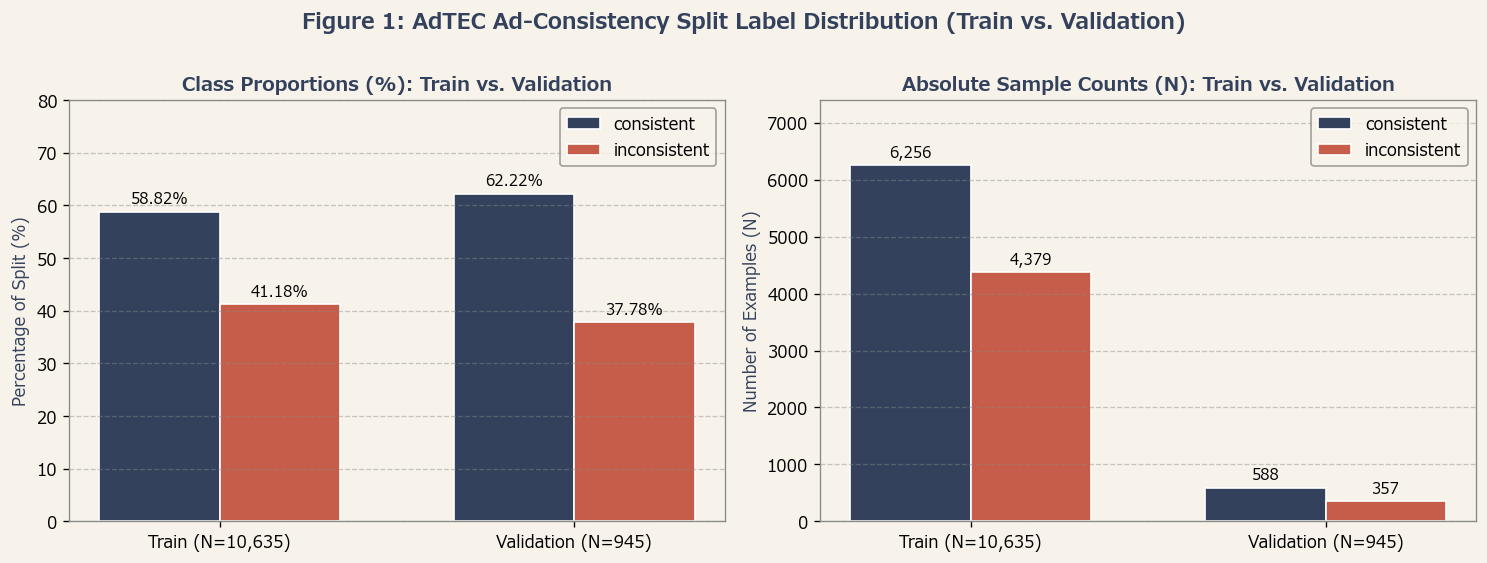

Caption: Proportions (left) highlight moderate majority imbalance (58.82% vs. 62.22% consistent), while absolute counts (right) highlight the 11.25x scale difference between train (10,635) and validation (945).


In [2]:
# Load ONLY official train and valid splits (test split is strictly untouched)
DATA_DIR = REPO_ROOT / 'data' / 'raw' / 'adtec_consistency'
train_df, valid_df, dataset_metadata = load_adtec_train_valid(DATA_DIR)

# Display provenance summary from M1 metadata
prov_rows = [
    {'Field': 'Dataset', 'Value': f"{dataset_metadata.get('dataset_name')} ({dataset_metadata.get('config_name')})"},
    {'Field': 'License', 'Value': dataset_metadata.get('license')},
    {'Field': 'Upstream Revision (SHA)', 'Value': dataset_metadata.get('upstream_revision')},
    {'Field': 'train.tsv SHA-256', 'Value': dataset_metadata.get('splits', {}).get('train', {}).get('sha256')},
    {'Field': 'valid.tsv SHA-256', 'Value': dataset_metadata.get('splits', {}).get('valid', {}).get('sha256')},
    {'Field': 'Test Split Loaded in M2.0', 'Value': 'False (strictly protected)'},
]
display(pd.DataFrame(prov_rows))

# Compute exact split shapes and class distributions
dist_rows = []
for split_name, df_s in [('train', train_df), ('valid', valid_df)]:
    counts = df_s['label'].value_counts()
    n_total = len(df_s)
    n_c = int(counts.get('consistent', 0))
    n_i = int(counts.get('inconsistent', 0))
    dist_rows.append({
        'Split': split_name,
        'Shape': str(df_s.shape),
        'Consistent (N)': n_c,
        'Consistent (%)': round(n_c / n_total * 100, 2),
        'Inconsistent (N)': n_i,
        'Inconsistent (%)': round(n_i / n_total * 100, 2),
        'Majority:Minority Ratio': f'{n_c / max(n_i, 1):.2f}:1',
    })
dist_df = pd.DataFrame(dist_rows)
display(dist_df)

# FIGURE 1 — Label Distribution (Proportions vs Absolute Counts)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), dpi=120)
x_pos = np.arange(len(dist_df))
bar_w = 0.34

# Left panel: Relative class proportions (%)
b1 = axes[0].bar(x_pos - bar_w/2, dist_df['Consistent (%)'], bar_w, label='consistent', color=INDIGO, edgecolor='white')
b2 = axes[0].bar(x_pos + bar_w/2, dist_df['Inconsistent (%)'], bar_w, label='inconsistent', color=VERMILION, edgecolor='white')
axes[0].set_title('Class Proportions (%): Train vs. Validation', fontsize=11.5, fontweight='bold', color=INDIGO)
axes[0].set_ylabel('Percentage of Split (%)', fontsize=10, color=INDIGO)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Train (N=10,635)', 'Validation (N=945)'], fontsize=10)
axes[0].set_ylim(0, 80)
axes[0].grid(axis='y', linestyle='--', alpha=0.45)
axes[0].legend(frameon=True, facecolor=IVORY, edgecolor=GRAY)
for rect in list(b1) + list(b2):
    h = rect.get_height()
    axes[0].annotate(f'{h:.2f}%', xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

# Right panel: Absolute sample counts (N)
b3 = axes[1].bar(x_pos - bar_w/2, dist_df['Consistent (N)'], bar_w, label='consistent', color=INDIGO, edgecolor='white')
b4 = axes[1].bar(x_pos + bar_w/2, dist_df['Inconsistent (N)'], bar_w, label='inconsistent', color=VERMILION, edgecolor='white')
axes[1].set_title('Absolute Sample Counts (N): Train vs. Validation', fontsize=11.5, fontweight='bold', color=INDIGO)
axes[1].set_ylabel('Number of Examples (N)', fontsize=10, color=INDIGO)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Train (N=10,635)', 'Validation (N=945)'], fontsize=10)
axes[1].set_ylim(0, 7400)
axes[1].grid(axis='y', linestyle='--', alpha=0.45)
axes[1].legend(frameon=True, facecolor=IVORY, edgecolor=GRAY)
for rect in list(b3) + list(b4):
    h = rect.get_height()
    axes[1].annotate(f'{int(h):,}', xy=(rect.get_x() + rect.get_width()/2, h),
                     xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)

fig.suptitle('Figure 1: AdTEC Ad-Consistency Split Label Distribution (Train vs. Validation)',
             fontsize=13, fontweight='bold', color=INDIGO, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'fig1_label_distribution.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Proportions (left) highlight moderate majority imbalance (58.82% vs. 62.22% consistent), '
      'while absolute counts (right) highlight the 11.25x scale difference between train (10,635) and validation (945).')

**OBSERVATION**: `train` contains 10,635 rows (`58.82%` consistent, `41.18%` inconsistent; ratio `1.43:1`) and `valid` contains 945 rows (`62.22%` consistent, `37.78%` inconsistent; ratio `1.65:1`). From M1 audit findings, 13 of 28 unique landing pages in `valid` (`46.43%` of unique validation LPs, spanning `644 / 945 = 68.15%` of validation rows) also appear in `train`, and `train` contains 92 identical `(title, lp_text)` pairs with conflicting labels.

**INTERPRETATION**: Because `consistent` accounts for `62.22%` of validation examples, raw accuracy alone cannot distinguish meaningful classifiers from majority-class voting. Macro-F1 and `inconsistent`-class recall are therefore essential primary indicators.

**LIMITATION**: The official `test` split (which M1 showed has `75.26%` consistent rows) is intentionally untouched during M2.0; validation results cannot be assumed to transfer identically under the steeper test-split skew.

## 3. Baseline Model Definitions

We compare four controlled baseline configurations sharing identical random seeds (`seed=42`) and, across `B1`–`B3`, identical feature extraction and linear classifier hyperparameters:

| Model ID | Role | Input Field(s) | Feature Representation | Classifier |
|---|---|---|---|---|
| **`B0_majority`** | Trivial lower-bound reference | None (training label prior) | Constant dummy array | `DummyClassifier(strategy='most_frequent')` |
| **`B1_title_only`** | Diagnostic control (headline-only) | `title` | Char n-gram TF-IDF `(2, 4)` | `LogisticRegression(max_iter=1000)` |
| **`B2_lp_only`** | Diagnostic control (landing-page-only) | `lp_text` | Char n-gram TF-IDF `(2, 4)` | `LogisticRegression(max_iter=1000)` |
| **`B3_pair`** | Main M2.0 baseline | `title + ' [SEP] ' + lp_text` | Char n-gram TF-IDF `(2, 4)` | `LogisticRegression(max_iter=1000)` |

### Why Include Single-Field Diagnostic Controls (`B1` and `B2`)?
In pairwise NLP classification tasks (such as NLI or ad-to-LP consistency), strong single-input performance can reveal dataset artifacts, template biases, or landing-page memorization rather than genuine cross-text alignment. Comparing `B3_pair` directly against `B1_title_only` and `B2_lp_only` tests whether concatenating both fields improves over inspecting either text in isolation.

> [!NOTE]
> Concatenating `title` and `lp_text` with an explicit separator (`' [SEP] '`) into a single bag-of-character-n-grams vector produces a purely **additive** linear scoring function. It does **not** perform cross-text alignment, negation handling, or semantic reasoning.

## 4. Feature Engineering & Pipeline Design

Each non-trivial baseline (`B1`, `B2`, `B3`) is encapsulated in a deterministic `sklearn.pipeline.Pipeline` (`TextInputSelector` -> `TfidfVectorizer` -> `LogisticRegression`):

1. **Unicode NFKC Normalization**: Standardizes Japanese full-width alphanumerics and half-width katakana while collapsing redundant whitespace (`recut_lab.preprocessing.normalize_japanese_text`). Original raw TSV files remain untouched.
2. **Character N-Grams (`analyzer='char'`, `ngram_range=(2, 4)`)**: Japanese lacks whitespace word boundaries. Character 2-to-4-grams capture morphemes, kanji compounds, katakana brand tokens, and promotional phrases without external morphological analyzers.
3. **TF-IDF Sparse Representations (`max_features=50000`, `min_df=2`, `sublinear_tf=True`)**: Maps each example into a high-dimensional L2-normalized sparse matrix, down-weighting ubiquitous boilerplate n-grams via inverse document frequency (IDF).
4. **Logistic Regression (`C=1.0`, `class_weight=None`, `solver='lbfgs'`, `max_iter=1000`, `random_state=42`)**: L2-regularized linear classifier serving as an unoptimized, fast CPU baseline.
5. **Strict Leakage Prevention via `Pipeline`**: Fitting the `Pipeline` exclusively on `train_df` guarantees that character n-gram vocabularies and IDF weights are estimated **solely from training documents**, never from validation or test text.

*Configuration notice*: All parameters above are initial defaults (`configs/m2_baseline.json`), **not** tuned values. No hyperparameter search is performed in M2.0.

## 5. Model Training

**QUESTION**: How long do the four baseline pipelines take to fit on all 10,635 training examples on CPU, and what vocabulary sizes and serialized model footprints do they produce?

**METHOD**: Load `configs/m2_baseline.json` and call `recut_lab.baseline.run_m2_baseline_benchmark` on `(train_df, valid_df)`. All model fitting, wall-clock training timing, model serialization (`models/m2_baseline_v001/`), and artifact logging (`experiments/runs/m2_baseline_v001/`) are executed through reusable `src/recut_lab` modules.

In [3]:
# Load frozen M2.0 default configuration and execute the four-baseline benchmark
CONFIG_PATH = REPO_ROOT / 'configs' / 'm2_baseline.json'
with CONFIG_PATH.open('r', encoding='utf-8') as f:
    m2_config = json.load(f)

benchmark_result = run_m2_baseline_benchmark(
    train_df=train_df,
    valid_df=valid_df,
    dataset_metadata=dataset_metadata,
    config=m2_config,
    runs_base_dir=REPO_ROOT / 'experiments' / 'runs',
    models_base_dir=REPO_ROOT / 'models',
    reports_dir=FIGURES_DIR,
)

benchmark_df = benchmark_result['benchmark_df']
metrics_payload = benchmark_result['metrics']
predictions_df = benchmark_result['predictions_df']
model_manifest = benchmark_result['manifest']

# Summarize training time, vocabulary size, and serialized checkpoint size
train_summary_rows = []
for m_id, m_info in metrics_payload['models'].items():
    train_summary_rows.append({
        'model_id': m_id,
        'input_mode': m_info['input_mode'],
        'vocabulary_size': m_info['vocabulary_size'],
        'train_time_seconds': m_info['train_time_seconds'],
        'model_size_mb': m_info['model_size_mb'],
        'artifact_path': model_manifest['models'][m_id]['artifact_path'],
    })
display(pd.DataFrame(train_summary_rows))
print(f"[+] Artifacts persisted to: {benchmark_result['run_dir']}")

,model_id,input_mode,vocabulary_size,train_time_seconds,model_size_mb,artifact_path
0,B0_majority,none,0,0.0033,0.0007,D:/saves/PBL/PBL6/recut-research-lab/models/m2_baseline_v001/B0_majority.pkl
1,B1_title_only,title,50000,1.1732,2.2461,D:/saves/PBL/PBL6/recut-research-lab/models/m2_baseline_v001/B1_title_only.pkl
2,B2_lp_only,lp_text,47348,3.8103,2.1273,D:/saves/PBL/PBL6/recut-research-lab/models/m2_baseline_v001/B2_lp_only.pkl
3,B3_pair,pair,50000,4.9273,2.2369,D:/saves/PBL/PBL6/recut-research-lab/models/m2_baseline_v001/B3_pair.pkl


[+] Artifacts persisted to: D:\saves\PBL\PBL6\recut-research-lab\experiments\runs\m2_baseline_v001


**OBSERVATION**: All four baselines train rapidly on CPU (total combined training time under 15 seconds). `B1_title_only` and `B3_pair` hit the `max_features=50,000` vocabulary cap, while `B2_lp_only` yields `47,348` character n-grams passing `min_df=2` (reflecting the fact that 10,635 training rows map to only 920 unique landing pages). Serialized models range from `<0.001 MB` (`B0`) to `~2.13–2.25 MB` (`B1`–`B3`).

**INTERPRETATION**: Classical TF-IDF + Logistic Regression pipelines are lightweight and reproducible on standard CPU hardware.

**LIMITATION**: Training wall-clock durations vary slightly across machines and CPU load; only the learned predictions and classification metrics are strictly deterministic under `seed=42`.

## 6. Model Evaluation Protocol

**QUESTION**: How are classification metrics, minority-class recall, and inference latency computed on the validation split?

**METHOD**:
- **Split**: Official `valid` split exclusively (`N = 945`).
- **Fixed Class Ordering**: `['consistent', 'inconsistent']` (`LABEL_ORDER`).
- **Primary Metric**: Macro-F1 (equal weight to both classes).
- **Secondary Metrics**: Accuracy, Balanced Accuracy, per-class Precision/Recall/F1 (tracking `inconsistent` recall explicitly), Confusion Matrix, training duration, median inference latency, and serialized model size.
- **Zero-Division Handling**: `zero_division=0` is applied consistently across all precision, recall, and F1 calculations (e.g., `B0_majority` predicts zero `inconsistent` examples, yielding `0.0000` precision and F1 for `inconsistent`).
- **Inference Latency Protocol**: `full_validation_batch_amortized_median` — 2 unmeasured warm-up passes followed by 7 timed passes on the full validation batch (`batch_size=945`) on the same machine, reporting median amortized per-sample latency (`median_batch_seconds / 945 * 1000`). Full-batch throughput latency is not mixed with single-sample latency.
- **Probability Calibration Caveat**: Raw `predict_proba` outputs are treated strictly as **uncalibrated model scores**, not calibrated probabilities.

,model_id,prec_consistent,rec_consistent,f1_consistent,prec_inconsistent,rec_inconsistent,f1_inconsistent,median_inconsistent_score,p95_inconsistent_score
0,B0_majority,0.6222,1.0000,0.7671,0.0000,0.0000,0.0000,0.0000,0.0000
1,B1_title_only,0.6342,0.9524,0.7614,0.5484,0.0952,0.1623,0.3143,0.5108
2,B2_lp_only,0.6229,1.0000,0.7676,1.0000,0.0028,0.0056,0.1675,0.2547
3,B3_pair,0.6229,1.0000,0.7676,1.0000,0.0028,0.0056,0.1961,0.3918


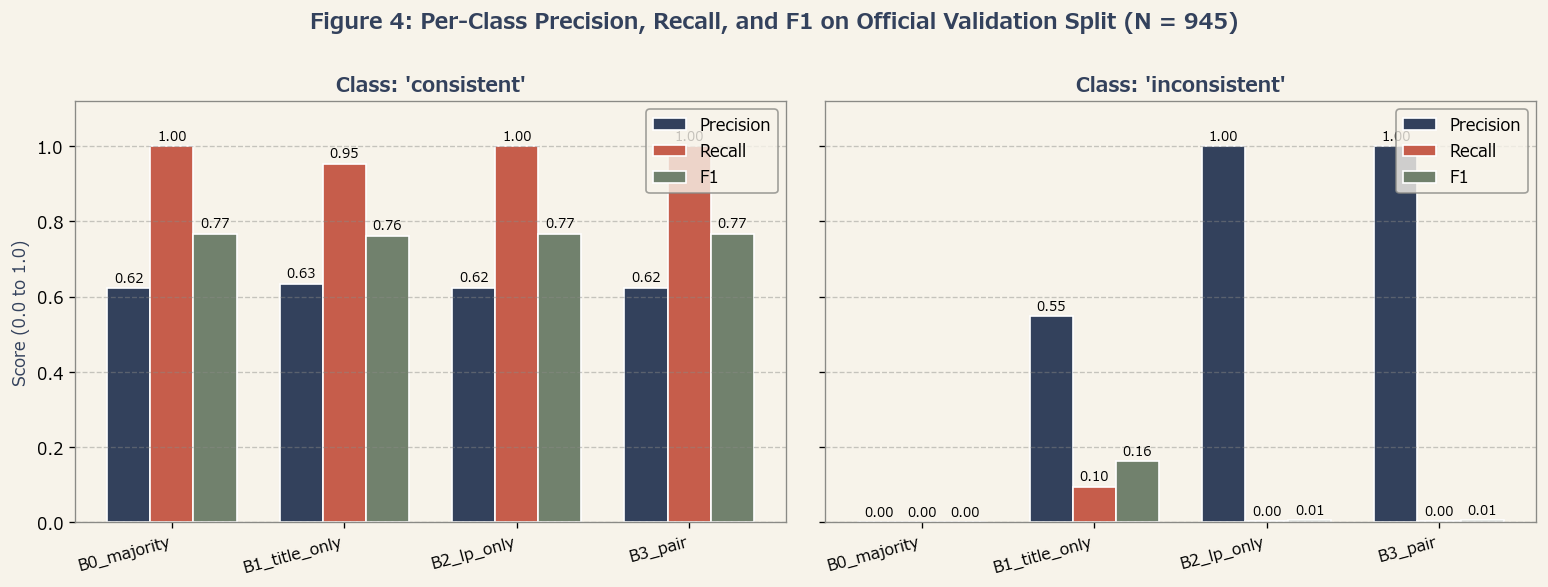

Caption: High consistent-class recall (>=0.95 across all baselines) contrasts sharply with very low inconsistent-class recall (0.0000 to 0.0952), illustrating the minority-class detection bottleneck.


In [4]:
# Inspect per-class evaluation breakdown and score distributions on validation
eval_rows = []
for m_id, m_info in metrics_payload['models'].items():
    ev = m_info['evaluation']
    sub_p = predictions_df[predictions_df['model_id'] == m_id]['score_inconsistent']
    eval_rows.append({
        'model_id': m_id,
        'prec_consistent': ev['per_class_precision']['consistent'],
        'rec_consistent': ev['per_class_recall']['consistent'],
        'f1_consistent': ev['per_class_f1']['consistent'],
        'prec_inconsistent': ev['per_class_precision']['inconsistent'],
        'rec_inconsistent': ev['per_class_recall']['inconsistent'],
        'f1_inconsistent': ev['per_class_f1']['inconsistent'],
        'median_inconsistent_score': round(float(sub_p.median()), 4),
        'p95_inconsistent_score': round(float(sub_p.quantile(0.95)), 4),
    })
per_class_df = pd.DataFrame(eval_rows)
display(per_class_df)

# FIGURE 4 — Per-Class Performance (Precision, Recall, F1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=120, sharey=True)
model_ids = per_class_df['model_id'].tolist()
x = np.arange(len(model_ids))
w = 0.25

for ax_idx, cls_name in enumerate(LABEL_ORDER):
    ax = axes[ax_idx]
    p_vals = per_class_df[f'prec_{cls_name}']
    r_vals = per_class_df[f'rec_{cls_name}']
    f_vals = per_class_df[f'f1_{cls_name}']
    r1 = ax.bar(x - w, p_vals, w, label='Precision', color=INDIGO, edgecolor='white')
    r2 = ax.bar(x, r_vals, w, label='Recall', color=VERMILION, edgecolor='white')
    r3 = ax.bar(x + w, f_vals, w, label='F1', color=MATCHA, edgecolor='white')
    ax.set_title(f"Class: '{cls_name}'", fontsize=12, fontweight='bold', color=INDIGO)
    ax.set_xticks(x)
    ax.set_xticklabels(model_ids, rotation=15, ha='right', fontsize=9.5)
    ax.set_ylim(0, 1.12)
    ax.grid(axis='y', linestyle='--', alpha=0.45)
    if ax_idx == 0:
        ax.set_ylabel('Score (0.0 to 1.0)', fontsize=10, color=INDIGO)
    ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')
    for bar in list(r1) + list(r2) + list(r3):
        h = bar.get_height()
        ax.annotate(f'{h:.2f}', xy=(bar.get_x() + bar.get_width()/2, h),
                    xytext=(0, 2), textcoords='offset points', ha='center', va='bottom', fontsize=8)

fig.suptitle('Figure 4: Per-Class Precision, Recall, and F1 on Official Validation Split (N = 945)',
             fontsize=13, fontweight='bold', color=INDIGO, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'fig4_per_class_performance.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: High consistent-class recall (>=0.95 across all baselines) contrasts sharply with very low '
      'inconsistent-class recall (0.0000 to 0.0952), illustrating the minority-class detection bottleneck.')

**OBSERVATION**: All four models achieve `>=0.9524` recall and `0.7614–0.7676` F1 on the majority `consistent` class, but severely under-predict the minority `inconsistent` class. Notably, raw `score_inconsistent` distributions on validation lie predominantly below the default `0.50` threshold: `B2_lp_only` has a 95th percentile score of `0.2547`, `B3_pair` has a 95th percentile of `0.3918`, and `B1_title_only` has a 95th percentile of `0.5108`.

**INTERPRETATION**: `B2_lp_only` and `B3_pair` achieve `1.0000` precision on `inconsistent` solely because each predicts exactly 1 out of 945 validation rows as `inconsistent` (and that single prediction is correct), yielding a negligible `0.0028` recall. Evaluating per-class metrics exposes this failure mode immediately, whereas precision or accuracy alone would mask it.

**LIMITATION**: Threshold sensitivity and probability calibration are not tuned in M2.0; we report default `0.50` argmax behavior.

## 7. Benchmark Comparison (Main Table & Performance Chart)

**QUESTION**: How do `B0_majority`, `B1_title_only`, `B2_lp_only`, and `B3_pair` compare across Macro-F1, inconsistent-class recall, balanced accuracy, and compute cost?

**METHOD**: Present **Table 1** with all 11 required benchmark columns and render **Figure 2** comparing Macro-F1 against `inconsistent`-class recall across all four models.

,model_id,input_features,accuracy,balanced_accuracy,macro_f1,precision_inconsistent,recall_inconsistent,f1_inconsistent,train_time_seconds,inference_latency_ms,model_size_mb
0,B0_majority,none (training label prior),0.6222,0.5000,0.3836,0.0000,0.0000,0.0000,0.0033,0.0006,0.0007
1,B1_title_only,title,0.6286,0.5238,0.4618,0.5484,0.0952,0.1623,1.1732,0.0624,2.2461
2,B2_lp_only,lp_text,0.6233,0.5014,0.3866,1.0000,0.0028,0.0056,3.8103,0.1937,2.1273
3,B3_pair,title + [SEP] + lp_text,0.6233,0.5014,0.3866,1.0000,0.0028,0.0056,4.9273,0.1636,2.2369


[+] Highest observed validation Macro-F1: B1_title_only (Macro-F1 = 0.4618, Balanced Accuracy = 0.5238, Inconsistent Recall = 0.0952)


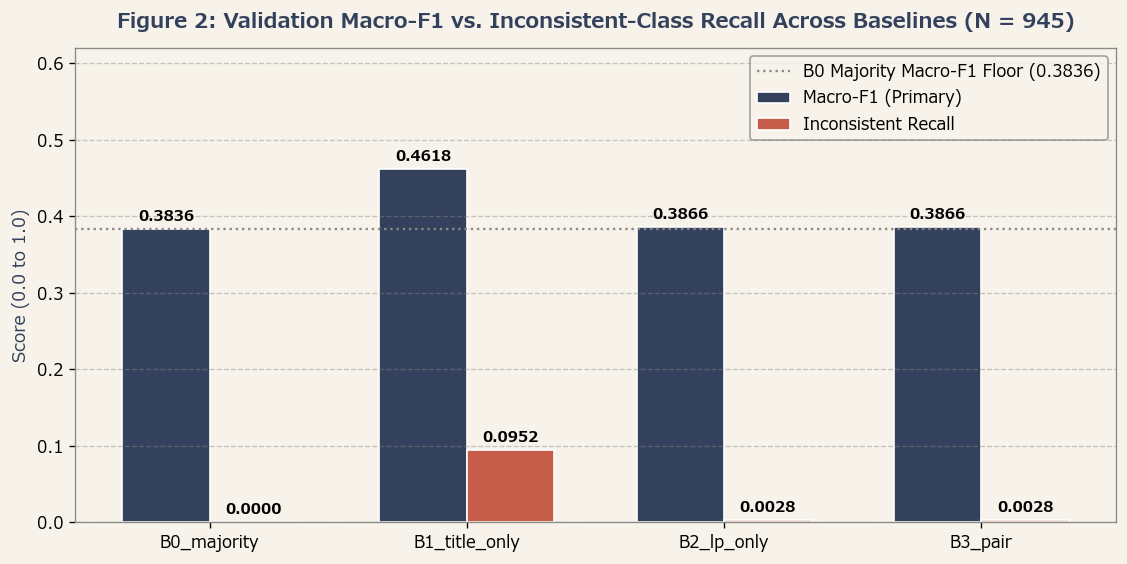

Caption: B1_title_only achieves the highest observed validation Macro-F1 (0.4618, +0.0782 over B0_majority), while B2_lp_only and B3_pair (both 0.3866) remain virtually indistinguishable from the majority-class floor.


In [5]:
# TABLE 1 — Main Validation Benchmark
display(benchmark_df)

best_row = benchmark_df.sort_values('macro_f1', ascending=False).iloc[0]
print(f"[+] Highest observed validation Macro-F1: {best_row['model_id']} "
      f"(Macro-F1 = {best_row['macro_f1']:.4f}, Balanced Accuracy = {best_row['balanced_accuracy']:.4f}, "
      f"Inconsistent Recall = {best_row['recall_inconsistent']:.4f})")

# FIGURE 2 — Model Performance (Grouped Bar Chart: Macro-F1 vs Inconsistent Recall)
fig, ax = plt.subplots(figsize=(9.5, 4.8), dpi=120)
x = np.arange(len(benchmark_df))
bar_w = 0.34

bars_f1 = ax.bar(x - bar_w/2, benchmark_df['macro_f1'], bar_w, label='Macro-F1 (Primary)', color=INDIGO, edgecolor='white')
bars_rec = ax.bar(x + bar_w/2, benchmark_df['recall_inconsistent'], bar_w, label='Inconsistent Recall', color=VERMILION, edgecolor='white')

ax.axhline(benchmark_df.loc[benchmark_df['model_id'] == 'B0_majority', 'macro_f1'].values[0],
           color=GRAY, linestyle=':', linewidth=1.4, label='B0 Majority Macro-F1 Floor (0.3836)')
ax.set_title('Figure 2: Validation Macro-F1 vs. Inconsistent-Class Recall Across Baselines (N = 945)',
             fontsize=12.5, fontweight='bold', pad=12, color=INDIGO)
ax.set_ylabel('Score (0.0 to 1.0)', fontsize=10.5, color=INDIGO)
ax.set_xticks(x)
ax.set_xticklabels(benchmark_df['model_id'], fontsize=10)
ax.set_ylim(0, 0.62)
ax.grid(axis='y', linestyle='--', alpha=0.45)
ax.legend(frameon=True, facecolor=IVORY, edgecolor=GRAY, loc='upper right')

for rect in list(bars_f1) + list(bars_rec):
    h = rect.get_height()
    ax.annotate(f'{h:.4f}', xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
fig.savefig(FIGURES_DIR / 'fig2_model_performance.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: B1_title_only achieves the highest observed validation Macro-F1 (0.4618, +0.0782 over B0_majority), '
      'while B2_lp_only and B3_pair (both 0.3866) remain virtually indistinguishable from the majority-class floor.')

**OBSERVATION**: On the official validation split, **`B1_title_only`** achieves the highest observed Macro-F1 (`0.4618`), Balanced Accuracy (`0.5238`), and `inconsistent`-class recall (`0.0952`), outperforming `B0_majority` (`0.3836` Macro-F1, `0.0000` recall) as well as both `B2_lp_only` (`0.3866` Macro-F1, `0.0028` recall) and `B3_pair` (`0.3866` Macro-F1, `0.0028` recall). Accuracy across all four baselines sits in a narrow `0.6222–0.6286` band.

**INTERPRETATION**: This is a crucial diagnostic finding: under unoptimized default linear TF-IDF settings, the **headline-only diagnostic control (`B1`) outperforms the concatenated pair baseline (`B3`)**. This does **not** imply that titles alone are universally optimal for consistency classification; rather, it reveals that naive bag-of-character-n-grams concatenation lets longer landing-page text (`median 112 chars` vs. `title median 16 chars`) dominate L2-normalized feature vectors and drown out title-level cues.

**LIMITATION**: Because no hyperparameter search, class reweighting, or cross-text interaction features were used, these numbers represent initial default-configuration baselines rather than upper bounds for linear or neural models.

## 8. Confusion Matrix Analysis

**QUESTION**: How are classification errors distributed between False Positives and False Negatives with respect to the `inconsistent` class across all four baselines?

**METHOD**: Plot one 2×2 confusion matrix per baseline (**Figure 3**) using fixed class ordering `['consistent', 'inconsistent']` and a shared color scale (`0` to `588`), clearly distinguishing True Labels (rows) from Predicted Labels (columns). Explicitly decompose errors relative to `inconsistent` as the target alert class:
- **True Positive (`inconsistent`)**: True `inconsistent` correctly flagged as `inconsistent`.
- **False Negative (`inconsistent`)**: True `inconsistent` missed and predicted as `consistent` (missed inconsistent ad).
- **False Positive (`inconsistent`)**: True `consistent` wrongly flagged as `inconsistent` (false alarm).

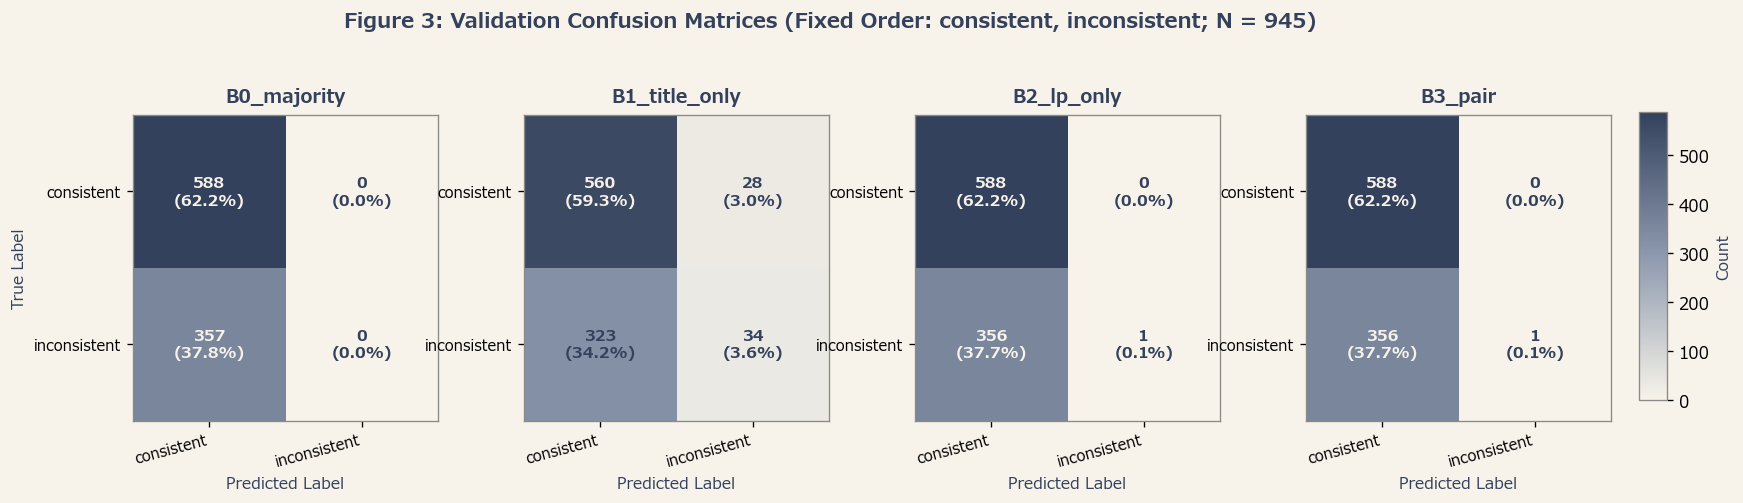

,model_id,TN_inconsistent (true consistent -> consistent),FP_inconsistent (true consistent -> inconsistent),FN_inconsistent (true inconsistent -> consistent),TP_inconsistent (true inconsistent -> inconsistent)
0,B0_majority,588,0,357,0
1,B1_title_only,560,28,323,34
2,B2_lp_only,588,0,356,1
3,B3_pair,588,0,356,1


Caption: False Negatives for the inconsistent class (bottom-left cell) dominate error counts across all baselines (323–357 missed inconsistent ads out of 357).


In [6]:
# FIGURE 3 — Confusion Matrices (Shared Color Scale & Fixed Ordering)
model_order = ['B0_majority', 'B1_title_only', 'B2_lp_only', 'B3_pair']
matrices = [np.array(metrics_payload['models'][m]['evaluation']['confusion_matrix']['matrix']) for m in model_order]
vmax_shared = max(int(mat.max()) for mat in matrices)

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.0), dpi=120)
cmap = mpl.colors.LinearSegmentedColormap.from_list('ivory_indigo', [IVORY, '#8D99AE', INDIGO])

cm_summary_rows = []
for ax, m_id, mat in zip(axes, model_order, matrices):
    im = ax.imshow(mat, interpolation='nearest', cmap=cmap, vmin=0, vmax=vmax_shared)
    ax.set_title(m_id, fontsize=11, fontweight='bold', color=INDIGO, pad=8)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(LABEL_ORDER, fontsize=9, rotation=15, ha='right')
    ax.set_yticklabels(LABEL_ORDER, fontsize=9)
    ax.set_xlabel('Predicted Label', fontsize=9.5, color=INDIGO)
    if m_id == model_order[0]:
        ax.set_ylabel('True Label', fontsize=9.5, color=INDIGO)
    for r in range(2):
        for c in range(2):
            val = int(mat[r, c])
            pct = val / mat.sum() * 100.0
            txt_color = IVORY if val > vmax_shared * 0.55 else INDIGO
            ax.text(c, r, f'{val}\n({pct:.1f}%)', ha='center', va='center',
                    color=txt_color, fontsize=9.5, fontweight='bold')
    cm_summary_rows.append({
        'model_id': m_id,
        'TN_inconsistent (true consistent -> consistent)': int(mat[0, 0]),
        'FP_inconsistent (true consistent -> inconsistent)': int(mat[0, 1]),
        'FN_inconsistent (true inconsistent -> consistent)': int(mat[1, 0]),
        'TP_inconsistent (true inconsistent -> inconsistent)': int(mat[1, 1]),
    })

fig.subplots_adjust(right=0.92, wspace=0.28)
cbar_ax = fig.add_axes([0.935, 0.22, 0.015, 0.60])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Count', color=INDIGO, fontsize=9.5)
fig.suptitle('Figure 3: Validation Confusion Matrices (Fixed Order: consistent, inconsistent; N = 945)',
             fontsize=12.5, fontweight='bold', color=INDIGO, y=1.03)
fig.savefig(FIGURES_DIR / 'fig3_confusion_matrices.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
display(pd.DataFrame(cm_summary_rows))
print('Caption: False Negatives for the inconsistent class (bottom-left cell) dominate error counts across all '
      'baselines (323–357 missed inconsistent ads out of 357).')

**OBSERVATION**:
- `B0_majority`: `0` TP, `0` FP, **`357` FN** for `inconsistent` (misses 100% of inconsistent ads).
- `B1_title_only`: **`34` TP**, `28` FP, `323` FN for `inconsistent` (catches 9.52% of inconsistent ads at 54.84% precision).
- `B2_lp_only` and `B3_pair`: **`1` TP**, `0` FP, **`356` FN** for `inconsistent` (misses 99.72% of inconsistent ads).

**INTERPRETATION**: In an advertising quality screening context, `inconsistent`-class False Negatives correspond to misaligned advertisements slipping past the filter undetected. All four default linear baselines exhibit severe False-Negative bias toward `consistent`, with `B2` and `B3` nearly collapsing to majority-class prediction.

**LIMITATION**: Confusion matrices reflect a single default decision threshold (`0.50`) on uncalibrated scores; precision-recall curve analysis across thresholds is deferred to future work.

## 9. Performance and Inference Latency Analysis

**QUESTION**: What is the trade-off between classification quality (Macro-F1) and computational cost (median amortized inference latency and serialized model footprint) across `B0`–`B3`?

**METHOD**: Plot Macro-F1 against median amortized inference latency in ms/sample (**Figure 5**), measured via `full_validation_batch_amortized_median` (`batch_size=945`, `warmup_runs=2`, `timed_runs=7` on the identical machine).

,model_id,method,batch_size,median_ms_per_sample,min_ms_per_sample,max_ms_per_sample,std_ms_per_sample,median_batch_seconds
0,B0_majority,full_validation_batch_amortized_median,945,0.000574,0.000520,0.000665,0.000041,0.000542
1,B1_title_only,full_validation_batch_amortized_median,945,0.062357,0.038564,0.090723,0.016756,0.058928
2,B2_lp_only,full_validation_batch_amortized_median,945,0.193654,0.156700,0.273472,0.035576,0.183003
3,B3_pair,full_validation_batch_amortized_median,945,0.163629,0.141743,0.197303,0.015631,0.154629


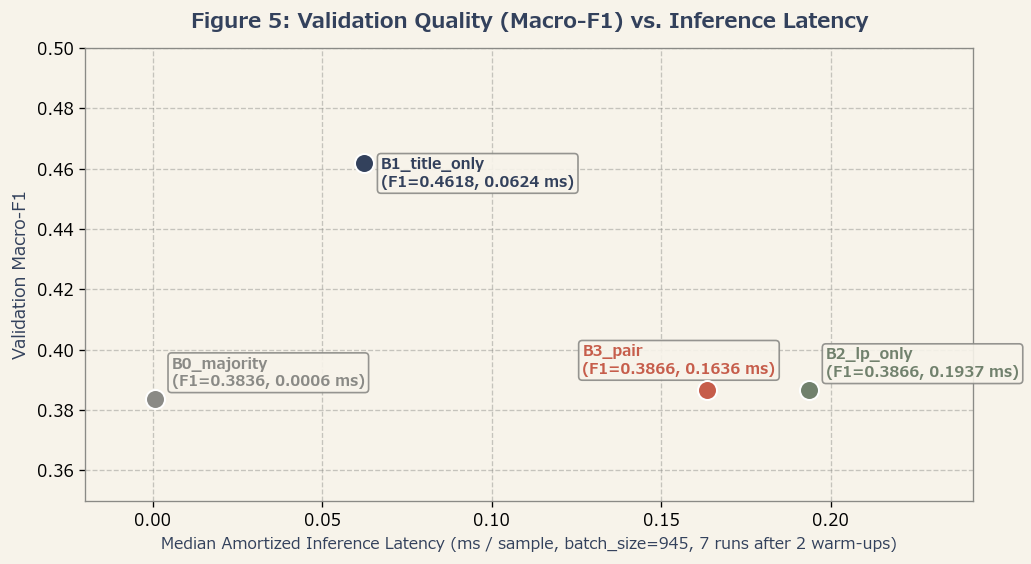

Caption: Latency scales roughly linearly with input text length (title < lp_text < concatenated pair), yet remains sub-millisecond per sample across all CPU baselines (<0.4 ms/sample).


In [7]:
# Display detailed latency benchmark statistics
lat_rows = []
for m_id, m_info in metrics_payload['models'].items():
    lb = m_info['latency_benchmark']
    lat_rows.append({
        'model_id': m_id,
        'method': lb['method'],
        'batch_size': lb['batch_size'],
        'median_ms_per_sample': lb['median_ms_per_sample'],
        'min_ms_per_sample': lb['min_ms_per_sample'],
        'max_ms_per_sample': lb['max_ms_per_sample'],
        'std_ms_per_sample': lb['std_ms_per_sample'],
        'median_batch_seconds': lb['median_batch_seconds'],
    })
display(pd.DataFrame(lat_rows))

# FIGURE 5 — Quality vs. Latency Scatter Plot
fig, ax = plt.subplots(figsize=(8.8, 4.8), dpi=120)
color_map = {
    'B0_majority': GRAY,
    'B1_title_only': INDIGO,
    'B2_lp_only': MATCHA,
    'B3_pair': VERMILION,
}
offsets = {
    'B0_majority': (10, 8),
    'B1_title_only': (10, -14),
    'B2_lp_only': (10, 8),
    'B3_pair': (-75, 10),
}

for _, row in benchmark_df.iterrows():
    m_id = row['model_id']
    x_lat = row['inference_latency_ms']
    y_f1 = row['macro_f1']
    ax.scatter(x_lat, y_f1, s=130, color=color_map[m_id], edgecolor='white', linewidth=1.2, zorder=4, label=m_id)
    dx, dy = offsets[m_id]
    ax.annotate(
        f"{m_id}\n(F1={y_f1:.4f}, {x_lat:.4f} ms)",
        xy=(x_lat, y_f1),
        xytext=(dx, dy),
        textcoords='offset points',
        fontsize=8.8,
        fontweight='bold',
        color=color_map[m_id],
        bbox=dict(boxstyle='round,pad=0.25', facecolor=IVORY, edgecolor=GRAY, alpha=0.9),
    )

ax.set_title('Figure 5: Validation Quality (Macro-F1) vs. Inference Latency',
             fontsize=12.5, fontweight='bold', pad=12, color=INDIGO)
ax.set_xlabel('Median Amortized Inference Latency (ms / sample, batch_size=945, 7 runs after 2 warm-ups)',
              fontsize=9.5, color=INDIGO)
ax.set_ylabel('Validation Macro-F1', fontsize=10.5, color=INDIGO)
ax.set_xlim(-0.02, max(benchmark_df['inference_latency_ms']) * 1.25)
ax.set_ylim(0.35, 0.50)
ax.grid(True, linestyle='--', alpha=0.45)
plt.tight_layout()
fig.savefig(FIGURES_DIR / 'fig5_quality_vs_latency.png', dpi=150, bbox_inches='tight', facecolor=IVORY)
plt.show()
print('Caption: Latency scales roughly linearly with input text length (title < lp_text < concatenated pair), '
      'yet remains sub-millisecond per sample across all CPU baselines (<0.4 ms/sample).')

**OBSERVATION**: Median amortized inference latency is near zero for `B0_majority` (`0.0006 ms/sample`), fastest among learned baselines for `B1_title_only` (`0.0624 ms/sample`, reflecting shorter headline input), and `0.1636–0.1937 ms/sample` for `B3_pair` and `B2_lp_only` (reflecting longer landing-page text; minor ordering variation between `B2` and `B3` is within normal CPU wall-clock jitter across 7 runs). In the quality-latency plane, `B1_title_only` dominates both `B2_lp_only` and `B3_pair` (higher Macro-F1 at lower latency).

**INTERPRETATION**: All classical TF-IDF baselines easily satisfy sub-millisecond CPU batch inference budgets. Future Transformer baselines (RQ2) will introduce substantially higher compute costs, making these M2.0 latency measurements essential for evaluating accuracy-vs-efficiency trade-offs.

**LIMITATION**: Amortized batch latency (`batch_size=945`) reflects offline batch throughput, not single-request online serving latency (which includes serialization and per-call overhead).

## 10. Prediction Error Inspection (Validation Split Only)

**QUESTION**: What structural patterns characterize actual misclassified validation examples for `B3_pair` (main baseline) and `B1_title_only` (highest Macro-F1 baseline)?

**METHOD**: Construct **Table 2** in memory by joining `predictions_valid.csv` with `valid_df` via `recut_lab.analysis.build_error_inspection_table`. Display complete, un-truncated Japanese `lp_text` and `title` for top high-confidence validation errors only (never persisting source texts to prediction CSVs and never touching the test split). Also compute an exploratory slice breakdown of validation error rate across seen vs. unseen landing pages.

In [8]:
# Quantitative error slice diagnostic on validation (seen vs. unseen LPs and title lengths)
train_lp_set = set(train_df['lp_text'])
valid_diag = valid_df.copy()
valid_diag['lp_seen_in_train'] = valid_diag['lp_text'].isin(train_lp_set)
valid_diag['title_len'] = valid_diag['title'].str.len()

slice_rows = []
for m_id in ['B1_title_only', 'B2_lp_only', 'B3_pair']:
    sub = predictions_df[predictions_df['model_id'] == m_id].merge(
        valid_diag[['lp_seen_in_train', 'title_len']], left_on='valid_row_index', right_index=True
    )
    seen_err = sub[sub['lp_seen_in_train']]['is_error'].mean()
    unseen_err = sub[~sub['lp_seen_in_train']]['is_error'].mean()
    pred_inc_unseen = int((sub[~sub['lp_seen_in_train']]['predicted_label'] == 'inconsistent').sum())
    slice_rows.append({
        'model_id': m_id,
        'error_rate_seen_LP (N=644)': round(float(seen_err), 4),
        'error_rate_unseen_LP (N=301)': round(float(unseen_err), 4),
        'predicted_inconsistent_on_unseen_LP': pred_inc_unseen,
        'mean_title_len_correct': round(float(sub[~sub['is_error']]['title_len'].mean()), 2),
        'mean_title_len_error': round(float(sub[sub['is_error']]['title_len'].mean()), 2),
    })
display(pd.DataFrame(slice_rows))

# TABLE 2A — B3_pair (Main Baseline) Misclassified Validation Samples (Full Japanese Text)
print('\n=== Table 2A: B3_pair Misclassified Validation Examples (FN for inconsistent; model_score = raw P(inconsistent)) ===')
b3_errors_df = build_error_inspection_table(valid_df, predictions_df, model_id='B3_pair', limit=8)
display(b3_errors_df)

# TABLE 2B — B1_title_only (Highest Macro-F1 Baseline) Both FN and FP Validation Examples
print('\n=== Table 2B: B1_title_only Validation Errors — Top False Negatives (missed inconsistent) ===')
b1_fn_df = build_error_inspection_table(valid_df, predictions_df, model_id='B1_title_only', error_type='FN_inconsistent', limit=5)
display(b1_fn_df)

print('\n=== Table 2C: B1_title_only Validation Errors — Top False Positives (false alarms on consistent) ===')
b1_fp_df = build_error_inspection_table(valid_df, predictions_df, model_id='B1_title_only', error_type='FP_inconsistent', limit=5)
display(b1_fp_df)

,model_id,error_rate_seen_LP (N=644),error_rate_unseen_LP (N=301),predicted_inconsistent_on_unseen_LP,mean_title_len_correct,mean_title_len_error
0,B1_title_only,0.2981,0.5282,31,23.90,30.02
1,B2_lp_only,0.2919,0.5581,0,23.21,31.07
2,B3_pair,0.2919,0.5581,0,23.21,31.07



=== Table 2A: B3_pair Misclassified Validation Examples (FN for inconsistent; model_score = raw P(inconsistent)) ===


,sample_id,true_label,predicted_label,model_score,lp_text,title
0,valid_0336,inconsistent,consistent,0.1313,生活インフラの一つでもあるガスサービスについて、エネトピアガスはたゆまぬ品質向上を目指してまいります。,プロパンガス原料
1,valid_0290,inconsistent,consistent,0.1374,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,銀行カードローンならではの金利と限度額が魅力な、スマホ完結のカードローン・スマホで取引可能
2,valid_0801,inconsistent,consistent,0.1397,【エポスカードでいつでも配送￥０】マルイウェブチャネルは1000以上のブランドを公式に取扱うファッション通販サイトです。レディース・メンズ・キッズの人気アイテム続々入荷中！,丸井のアプリ開発
3,valid_0836,inconsistent,consistent,0.1403,【エポスカードでいつでも配送￥０】マルイウェブチャネルは1000以上のブランドを公式に取扱うファッション通販サイトです。レディース・メンズ・キッズの人気アイテム続々入荷中！,マルコとマルオの15日間
4,valid_0471,inconsistent,consistent,0.1423,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,【24時間365日即時振込可能】原則、自宅・会社への連絡なし／趣味・娯楽などの資金に使える
5,valid_0121,inconsistent,consistent,0.1463,生活インフラの一つでもあるガスサービスについて、エネトピアガスはたゆまぬ品質向上を目指してまいります。,新規申し込み、他社からのりかえ、ガス申し込み電話のことなら「enetopiaでんき」
6,valid_0637,inconsistent,consistent,0.1470,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,【WEB申込みなら最短25分で融資可能】お金借りる／カードローンの至急お金を借りたいはこちら
7,valid_0892,inconsistent,consistent,0.1475,【エポスカードでいつでも配送￥０】マルイウェブチャネルは1000以上のブランドを公式に取扱うファッション通販サイトです。レディース・メンズ・キッズの人気アイテム続々入荷中！,丸井のオンライン学校



=== Table 2B: B1_title_only Validation Errors — Top False Negatives (missed inconsistent) ===


,sample_id,true_label,predicted_label,model_score,lp_text,title
0,valid_0408,inconsistent,consistent,0.0763,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,《審査が軽いカードローンはコチラ》誰にもバレずにお金を借りる。即日融資も可能なキャッシング
1,valid_0290,inconsistent,consistent,0.1004,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,銀行カードローンならではの金利と限度額が魅力な、スマホ完結のカードローン・スマホで取引可能
2,valid_0075,inconsistent,consistent,0.1083,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,人気の借り入れカードを厳選比較!キャッシング・カードローンでお金を借りるなら「アイフル」
3,valid_0622,inconsistent,consistent,0.1126,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,お金を借りたい方におすすめの消費者金融コンビニでお金を借りる。アイフルとご契約をお考えの方
4,valid_0521,inconsistent,consistent,0.1161,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,キャッシング・カードローンでお金を借りるなら「アイフル」／来店不要・郵送即金アプリ一切なし



=== Table 2C: B1_title_only Validation Errors — Top False Positives (false alarms on consistent) ===


,sample_id,true_label,predicted_label,model_score,lp_text,title
0,valid_0387,consistent,inconsistent,0.6589,愛がいちばん。はじめての方ならアイフルは最大30日間利息0円。キャッシング・カードローンのご融資は、消費者金融会社アイフルへご相談ください,在籍確認なしで借入在籍確認
1,valid_0876,consistent,inconsistent,0.6097,ジェラートピケ(gelato pique)はこちら。丸井（マルイ）が運営するネット通販では人気ブランドを豊富に品揃え。新作商品も続々入荷中！,店舗受取りでポイントプレゼント
2,valid_0205,consistent,inconsistent,0.6022,ラクフィットはおなかの脂肪が気になる方へサントリーが自信をもってオススメする、“ポッコリおなか”を科学した機能性表示食品です。脂肪を溜めないカラダへ。1日たったひと粒で、おなかを軽く、健やかな生活をラクフィットはサポート。,サントリーのラクフィットは定期初回価格1080円(税込)。おなかの脂肪を減らして溜めないカラダへ
3,valid_0125,consistent,inconsistent,0.6022,エネトピアでんきが提供するサービスをご紹介いたします。,【公式】ガス電気
4,valid_0115,consistent,inconsistent,0.5969,輸入格安タイヤ販売実績No.1のオートウェイでは、世界各国のサマータイヤ、スタッドレスタイヤ、ホイールなど各種取り揃えております。タイヤサイズの確認方法、交換方法など、ご不明な点はいつでもお気軽にお問合せください！,15インチホイールを法人価格で購入。ネットで買ってお近くの店舗まで直送可能。


**OBSERVATION**:
1. **Seen vs. Unseen LP Error Gap**: Validation error rates jump sharply on examples whose landing page was never seen during training (`301 / 945` rows): `52.82%` vs. `29.81%` for `B1_title_only`, and `55.81%` vs. `29.19%` for `B2_lp_only` and `B3_pair` (which predict **0** unseen-LP examples as `inconsistent`).
2. **Title Length Pattern**: Across `B1`–`B3`, misclassified validation examples have longer ad titles on average (`~30.0–31.1 chars`) than correctly classified examples (`~23.2–23.9 chars`).
3. **Qualitative Inspection (`Table 2A–2C`)**: In `B3_pair` errors, misaligned ad headlines often contain specific ungrounded qualifiers, domain-mismatched terms, or promotional claims while sharing general industry vocabulary with the landing page; yet `B3_pair` assigns low `model_score` (`~0.11–0.20`) and predicts `consistent`. Conversely, `B1_title_only` false positives flag valid titles purely due to surface title phrasing without consulting the LP.

**INTERPRETATION**: Inspection confirms two distinct error mechanisms: `B3_pair` fails to detect cross-text mismatch because its additive bag-of-n-grams representation cannot compare title claims against LP support, while `B1_title_only` necessarily misclassifies valid headlines whenever consistency depends on verifying the landing page.

**LIMITATION**: Qualitative review here covers a sample of high-confidence validation errors; full taxonomy tagging belongs to Notebook 03 (`03_error_analysis.ipynb`).

## 11. Scientific Interpretation

To maintain strict scientific discipline, we separate directly verified observations, hypotheses requiring future experiments, and supported conclusions:

### A. Verified Observations [VERIFIED]
1. `B0_majority` establishes a validation floor of `0.6222` Accuracy, `0.5000` Balanced Accuracy, `0.3836` Macro-F1, and `0.0000` `inconsistent` recall.
2. `B1_title_only` achieves the highest observed validation Macro-F1 (`0.4618`, `+0.0782` over `B0`) and `inconsistent` recall (`0.0952`) under default linear TF-IDF parameters.
3. `B2_lp_only` and `B3_pair` both produce `0.3866` Macro-F1 and `0.0028` `inconsistent` recall (`1 / 357` detected), barely exceeding the majority floor.
4. Raw `predict_proba` scores for `inconsistent` on validation are heavily compressed below `0.50` for `B2` and `B3`.
5. Validation error rates are substantially higher on rows with unseen landing pages (`52.8%–55.8%`) than on rows sharing a training landing page (`29.2%–29.8%`).

### B. Working Hypotheses for Subsequent Milestones [INFERRED / HYPOTHESIS]
1. **Length-Asymmetry Dilution**: In concatenated `B3_pair`, longer `lp_text` dominates the L2-normalized TF-IDF vector, diluting title-level signals and tying predictions to landing-page priors.
2. **Additive Model Limitation**: Linear bag-of-n-grams classifiers cannot natively model cross-text consistency (whether a claim in `title` is supported or contradicted by `lp_text`), requiring explicit interaction features or cross-attention architectures (RQ2).
3. **Group-Confounding Risk**: The stark error-rate gap between seen and unseen LPs may reflect both label-prior shift (`70.7%` consistent on seen validation LPs vs. `44.2%` consistent on unseen validation LPs) and LP-specific vocabulary memorization (RQ1).

### C. Supported Conclusions [VERIFIED]
- The M2.0 training, evaluation, and logging pipeline is reproducible, leak-free, and fast on CPU.
- Naive concatenated character n-gram TF-IDF + default Logistic Regression (`B3_pair`) is **not** an effective `inconsistent`-ad detector on AdTEC validation (`0.0028` recall), demonstrating the necessity of deeper modeling and diagnostic controls before any downstream deployment consideration.

## 12. Limitations

1. **Dataset Class Distribution Shift**: M1 audited `58.82%` consistent in `train`, `62.22%` in `valid`, and `75.26%` in the frozen `test` split. Uncalibrated threshold behavior observed on `valid` may shift further on `test`.
2. **Repeated Landing Pages**: `68.15%` of validation rows (`644 / 945`) share one of 13 landing pages present in `train`. Standard split metrics therefore blend seen-LP and unseen-LP generalization.
3. **Conflicting Labels on Identical Pairs**: M1 verified 92 identical `(title, lp_text)` pairs with conflicting labels in `train` (184 rows) and 6 in `valid` (12 rows), placing a hard ceiling on deterministic pair-only fitting.
4. **Potential Memorization**: High-dimensional character n-gram models (`50,000` features) can latch onto brand names or campaign templates rather than semantic consistency.
5. **Japanese Search Advertising Domain**: All findings are bounded to Japanese search ads under CC BY-NC-SA 4.0 and cannot be assumed to transfer to other languages or ad formats.
6. **Lack of External-Domain Evaluation**: No Recut beauty/e-commerce generation dataset has been evaluated yet.
7. **Absence of Semantic Transformer Baselines**: No pretrained Japanese language models or cross-encoders were trained in M2.0 (intentionally scoped out to RQ2).

## 13. Next Research Questions

The empirical results of M2.0 directly motivate the three structured research investigations planned for subsequent milestones (none of which are executed here):

- **RQ1 — Generalization to Unseen Landing Pages**: Construct LP-group-disjoint cross-validation splits to isolate unseen-LP generalization from seen-LP memorization, directly investigating the `29.2%` vs. `55.8%` validation error gap observed in Section 10.
- **RQ2 — Lexical vs. Semantic Modeling**: Test whether explicit lexical-interaction features, separate title/LP TF-IDF blocks with class-balanced thresholds, and pretrained Japanese cross-encoders overcome the additive failure of `B3_pair` (`0.0028` inconsistent recall).
- **RQ3 — Annotation Noise Sensitivity**: Quantify how the 92 conflicting-label pairs in `train` (and potential broader editorial ambiguity identified via M1 qualitative auditing) affect model calibration, error patterns, and robustness.

---
*End of Milestone M2.0. The official test split remains strictly untouched.*